# 사용성 자체 평가: 시연 기록으로 본 가이드 6개 항목 (11/04)

가이드 "모델 성능 및 서비스 사용성 평가"의 6개 항목(정확도와 적합도, 일관성과 안정성, 응답 속도와 부하 처리, 유저 중심 인터페이스, 서비스 완성도, 제어 가능성)을 혼자 평가한다. 10/20에 범위에서 뺐다가, 11/04 시연 영상을 찍은 뒤 영상과 앱 기록을 근거로 혼자 평가하기로 했다(11/04 결정). 다른 사람에게 써 보게 하는 평가는 하지 않는다.

- 시연: 11/04 14:21:14부터 12분 53초 동안 앱으로 새 게임 "리치의 모험"을 등록하고 A → B → C → F → D → 상세 페이지를 차례로 만든 녹화(`E:\캡쳐\2026-11-04 14-21-14.mkv`, OBS). 이 노트북의 "원본 영상 시각"은 이 녹화의 시각이다.
- 읽는 기록 (모두 시연 중 앱이 남긴 것, 새로 생성하지 않음)
  - `outputs/app/app.db`: 요청(jobs)의 입력·결과·요청 시각·끝난 시각
  - `outputs/app/stage_times.csv`: 단계별 시간(모듈 불러오기, 모델 로드, 실제 생성)
  - `outputs/app/worker.log`: 워커 진행·오류 기록
- 기존 실험 결과는 README "주요 결과" 표의 값을 노트북 번호와 함께 인용한다.
- 시연 뒤(11/04) `src/app/core/worker.py`의 상태 파일 저장을 고쳤다(아래 "워커 오류" 절). 이 노트북의 기록은 고치기 전 것이다.
- 기록 (`outputs/usability/`): `ue_jobs.csv`, `ue_stages.csv`, `ue_worker_errors.csv`, `ue_wait.png`, `ue_worker_errors.png`
- GPU를 쓰지 않고, 몇 초 안에 끝난다.

## 설정

In [1]:
import importlib.metadata as md_
import json
import re
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import font_manager

ROOT = Path('..')
APP = ROOT / 'outputs' / 'app'
OUT_DIR = ROOT / 'outputs' / 'usability'
OUT_DIR.mkdir(parents=True, exist_ok=True)
DB, STAGE_CSV, WORKER_LOG = APP / 'app.db', APP / 'stage_times.csv', APP / 'worker.log'
for p in (DB, STAGE_CSV, WORKER_LOG):
    assert p.exists(), p

_ko = [f.name for f in font_manager.fontManager.ttflist if f.name in ('Malgun Gothic', 'Noto Sans CJK KR')]
if _ko:
    plt.rcParams['font.family'] = _ko[0]
plt.rcParams['axes.unicode_minus'] = False

# 녹화 파일 이름(2026-11-04 14-21-14)이 녹화 시작 시각이고, 길이는 ffprobe로 잰 773.368초
DEMO_START = pd.Timestamp('2026-11-04 14:21:14')
DEMO_END = DEMO_START + pd.Timedelta(seconds=773.368)
TZ = 'Asia/Seoul'


def kst(sec):
    return pd.to_datetime(sec, unit='s', utc=True).dt.tz_convert(TZ).dt.tz_localize(None)


def vtime(t):
    s = (t - DEMO_START).total_seconds()
    return f'{int(s // 60)}:{int(s % 60):02d}' if pd.notna(s) else ''


for p in ['pandas', 'numpy', 'matplotlib']:
    print(f'{p} {md_.version(p)}')
print('시연 구간:', DEMO_START, '~', DEMO_END.strftime('%H:%M:%S'))

pandas 3.0.6
numpy 2.2.6
matplotlib 3.11.2
시연 구간: 2026-11-04 14:21:14 ~ 14:34:07


## 시연 요청 (app.db)

시연 구간 안에 들어온 요청이다. "요청→끝"은 요청 버튼을 누른 시각부터 결과가 저장된 시각까지로, 사용자가 실제로 기다린 시간이다. C(#24)와 F(#25)는 모델 단계 없이 끝나는 요청이다(C는 B #23 그림을 가져옴, F는 미리 만든 후보 중 고르기).

In [2]:
con = sqlite3.connect(f'file:{DB.resolve().as_posix()}?mode=ro', uri=True)
jobs = pd.read_sql('select * from jobs', con)
games = pd.read_sql('select * from games', con).set_index('id')
for c in ['created', 'started', 'ended']:
    jobs[c + '_t'] = kst(jobs[c])
J = jobs[(jobs.created_t >= DEMO_START) & (jobs.created_t <= DEMO_END)].copy().sort_values('id')
J['game'] = J.game_id.map(games.name)
J['stages_n'] = J.stages.map(lambda s: len(json.loads(s)))
J['total_sec'] = (J.ended - J.created).round(2)
J['영상 시각(요청)'] = J.created_t.map(vtime)
J['영상 시각(끝)'] = J.ended_t.map(vtime)
show = J[['id', 'game', 'kind', 'title', 'stages', 'status', '영상 시각(요청)', '영상 시각(끝)', 'total_sec']]
display(show.rename(columns={'total_sec': '요청→끝(초)'}))
J.drop(columns=['params', 'result']).to_csv(OUT_DIR / 'ue_jobs.csv', index=False, encoding='utf-8-sig')
print('요청', len(J), '건, 상태:', J.status.value_counts().to_dict())
R = {int(r.id): json.loads(r.result) for r in J.itertuples()}
P = {int(r.id): json.loads(r.params) for r in J.itertuples()}

,id,game,kind,title,stages,status,영상 시각(요청),영상 시각(끝),요청→끝(초)
20,21,리치의 모험,a,A 홍보 문구,"[""copy""]",done,1:12,4:30,198.41
21,22,리치의 모험,b_convert,B 장면·문구 변환,"[""copy""]",done,5:01,5:41,40.10
22,23,리치의 모험,b_banner,B 이벤트 배너,"[""c_image"", ""compose""]",done,5:50,6:50,59.86
23,24,리치의 모험,c_image,C 그림체 이미지 (B #23 가져옴),[],done,7:45,,NaN
24,25,리치의 모험,f_pick,F 고른 목업,[],done,8:43,8:43,0.00
25,26,리치의 모험,d,D 굿즈 배경 (YR1n · 카페),"[""mask"", ""y"", ""iclight""]",done,8:55,10:48,112.91
26,27,리치의 모험,page,상세 페이지,"[""copy"", ""compose""]",done,11:09,12:12,62.87


요청 7 건, 상태: {'done': 7}


## 시연 결과 문구와 자동 검사 (app.db)

요청별 입력과 결과에서 평가에 쓰는 값만 뽑는다.

In [3]:
a = R[21]['copy']['intro']
print('[#21 A 홍보 문구] 입력:', {k: P[21][k] for k in ('points', 'must', 'tone')})
print('  첫 생성 문제:', a['first_problems'])
print('  생성', a['n_gen'], '번 · 호출', a['n_calls'], '번 → 최종 문제', a['problems'], '| 생성', a['sec'], '초')
fin = json.loads(a['text'])
print('  store:', fin['store'])
print('  sns:', fin['sns'])
cand = [json.loads(t) for t in a['texts_all']]
keys = ['붉은 달', '네크로맨서', P[21]['must']]
print('  후보', len(cand), '개 중 주제어 포함:', {k: sum(k in ' '.join(c['store']) + c['sns'] for c in cand) for k in keys})

b = R[22]['convert']
print('\n[#22 B 변환] 요청:', P[22]['request'])
print('  장면 태그:', b['scene'])
print('  제목:', b['title'], '| 부제:', b['sub'], '| 문제', b['problems'], '| 생성', b['sec'], '초')
print('  #23 배너 입력 장면 태그가 #22 변환 결과와 같음(사용자가 고치지 않음):', P[23]['scene'] == b['scene'])
print('  #23 글자 대비 (기준 3.0):', [(c['text'], round(c['contrast_p90'], 2)) for c in R[23]['contrast']])

print('\n[#24 C]', J.set_index('id').loc[24, 'title'], '| 그림:', R[24]['image'])
g4 = games.loc[J.set_index('id').loc[21, 'game_id']]
print('  게임', g4['name'], '| LoRA:', repr(g4['lora']), '| 그림체 태그:', repr(json.loads(g4['style']).get('tags')))

print('\n[#25 F]', {k: P[25][k] for k in ('kind', 'cand')}, '| 합성', R[25]['sec'], '초')
d = R[26]
print('\n[#26 D]', {k: P[26][k] for k in ('kind', 'scene', 'method')})
print('  Y 시도:', [(t['seed'], '검은 띠' if t['band'] else '통과') for t in d['y_tries']], '→ 쓴 seed', d['y_used_seed'])

pg = R[27]['copy']
print('\n[#27 상세 페이지] 직접 넣은 문구:', {k: v for k, v in P[27]['texts'].items() if v})
for k in ('title', 'mockup', 'staging'):
    print(f'  {k}:', pg[k]['lines'], '| 첫 생성 문제', pg[k]['first_problems'])

[#21 A 홍보 문구] 입력: {'points': ['신규출시'], 'must': '신규출시게임', 'tone': '친근하게'}
  첫 생성 문제: ['sns는 정확히 1문장이어야 하는데 2문장이다.', '꼭 넣을 문구 "신규출시게임"이 문장 앞이나 뒤에 따로 붙어 있다. sns 문장의 일부로 자연스럽게 넣어야 한다.']
  생성 5 번 · 호출 2 번 → 최종 문제 [] | 생성 23.18 초
  store: ['붉은 달 아래 네크로맨서 리치가 무기를 휘두르는 야수적인 모험, 신규출시게임으로 여러분의 화면을 장악합니다.', '사람이 아닌 죽음의 군대를 이겨내는 긴장감 넘치는 전투를 경험해 보세요.']
  sns: 붉은 달 아래 네크로맨서 리치가 무기를 휘두르며 죽음의 군대를 이겨내는 신규출시게임, 지금 바로 만나보세요.
  후보 5 개 중 주제어 포함: {'붉은 달': 5, '네크로맨서': 5, '신규출시게임': 5}

[#22 B 변환] 요청: 붉은 달 아래 네크로맨서 리치가 무기를 휘두르며 죽음의 군대를 이겨내는 신규출시게임, 지금 바로 만나보세요.
  장면 태그: red moon, necromancer, battlefield, dark armor, bloodied sword, undead army, stormy sky, glowing runes, shadowy forest, moonlit combat
  제목: 네크로맨서 리치, 붉은 달 아래 | 부제: 지금 바로 만나보세요 | 문제 [] | 생성 5.56 초
  #23 배너 입력 장면 태그가 #22 변환 결과와 같음(사용자가 고치지 않음): True
  #23 글자 대비 (기준 3.0): [('네크로맨서 리치, 붉은 달', 13.33), ('아래', 14.75), ('지금 바로 만나보세요', 13.31)]

[#24 C] C 그림체 이미지 (B #23 가져옴) | 그림: outputs/app/jobs/00023/banner_raw.png
  게임 리치의 모험 | LoRA: '' | 그림체 태그: ''

## 단계별 시간 (stage_times.csv)

- `wall_sec`: 단계 전체(별도 프로세스 시작~끝)
- `import_sec`: 모듈 불러오기, `load_sec`: 모델 로드, `items_sec`: 실제 생성 합
- `prep_sec` = `wall_sec` − `import_sec` − `load_sec` − `items_sec`: 프로세스 시작·파이썬 준비 등 위 셋에 들지 않는 시간

In [4]:
st = pd.read_csv(STAGE_CSV, keep_default_na=False)
for c in ['wall_sec', 'import_sec', 'load_sec', 'extra_load_sec', 'items_sec', 'fixed_sec', 'peak_vram_gb']:
    st[c] = pd.to_numeric(st[c], errors='coerce').fillna(0.0)
st['started_t'] = pd.to_datetime(st.started)
S = st[(st.started_t >= DEMO_START) & (st.started_t <= DEMO_END)].copy()
S['job_ids'] = S.job_ids.map(json.loads)
S['load_all'] = S.load_sec + S.extra_load_sec
S['prep_sec'] = (S.wall_sec - S.import_sec - S.load_all - S.items_sec).clip(lower=0).round(2)
S['생성 비율'] = (S.items_sec / S.wall_sec).round(3)
display(S[['stage', 'model', 'started', 'job_ids', 'wall_sec', 'import_sec', 'load_all', 'items_sec', 'prep_sec', '생성 비율',
           'peak_vram_gb']].rename(columns={'load_all': 'load_sec'}))
S.to_csv(OUT_DIR / 'ue_stages.csv', index=False, encoding='utf-8-sig')
m = S[S.stage != 'compose']
print('모델 단계', len(m), '개: 실제 생성', round(m.items_sec.sum(), 2), '초 / 전체', round(m.wall_sec.sum(), 2), '초 =',
      round(m.items_sec.sum() / m.wall_sec.sum(), 3))

,stage,model,started,job_ids,wall_sec,import_sec,load_sec,items_sec,prep_sec,생성 비율,peak_vram_gb
29,copy,Qwen/Qwen3-VL-8B-Instruct,2026-11-04 14:24:48,[21],56.51,2.40,14.64,23.18,16.29,0.410,18.17
30,copy,Qwen/Qwen3-VL-8B-Instruct,2026-11-04 14:26:16,[22],38.60,2.41,14.39,5.56,16.24,0.144,16.42
31,c_image,cagliostrolab/animagine-xl-4.0 + IP-Adapter (+...,2026-11-04 14:27:05,[23],59.08,2.37,20.38,10.92,25.41,0.185,12.99
32,compose,Pillow · Chromium,2026-11-04 14:28:04,[23],0.20,0.00,0.00,0.18,0.02,0.900,0.00
33,mask,ZhengPeng7/BiRefNet,2026-11-04 14:30:10,[26],21.60,2.47,3.45,0.92,14.76,0.043,3.12
34,y,yahoo-inc/photo-background-generation,2026-11-04 14:30:32,[26],44.37,2.46,9.66,5.50,26.75,0.124,10.08
35,iclight,stablediffusionapi/realistic-vision-v51 + icli...,2026-11-04 14:31:17,[26],45.71,2.41,8.23,9.93,25.14,0.217,4.49
36,copy,Qwen/Qwen3-VL-8B-Instruct,2026-11-04 14:32:24,[27],53.92,2.44,20.56,14.70,16.22,0.273,16.78
37,compose,Pillow · Chromium,2026-11-04 14:33:18,[27],7.38,0.00,0.00,7.37,0.01,0.999,0.00


모델 단계 7 개: 실제 생성 70.71 초 / 전체 319.79 초 = 0.221


## 그래프: 요청별 기다린 시간 나누기

요청→끝 시간을 단계 기록으로 나눈다. 단계 기록에 들지 않는 나머지("단계 밖")는 대기열 대기, 실패한 시도, 워커 재시작 등이다. 단계 하나가 요청 여러 개를 함께 처리하면 그 시간을 요청마다 그대로 넣는다(시연에서는 모두 요청 1개).

,id,label,요청→끝,실제 생성,모델 로드,모듈 불러오기,프로세스 준비 등,단계 밖 (대기·실패한 시도·재시작)
0,21,#21 A 홍보 문구,198.41,23.18,14.64,2.40,16.29,141.90
1,22,#22 B 장면·문구 변환,40.10,5.56,14.39,2.41,16.24,1.50
2,23,#23 B 이벤트 배너,59.86,11.10,20.38,2.37,25.43,0.58
3,26,#26 D 굿즈 배경 (YR1n · 카페),112.91,16.35,21.34,7.34,66.65,1.23
4,27,#27 상세 페이지,62.87,22.07,20.56,2.44,16.23,1.57


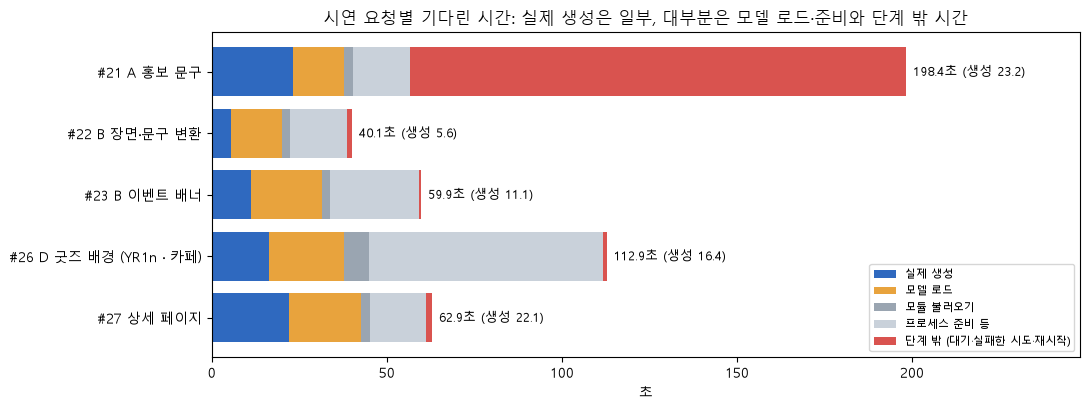

In [5]:
parts = ['items_sec', 'load_all', 'import_sec', 'prep_sec']
names = {'items_sec': '실제 생성', 'load_all': '모델 로드', 'import_sec': '모듈 불러오기', 'prep_sec': '프로세스 준비 등', 'outside': '단계 밖 (대기·실패한 시도·재시작)'}
rows = []
for r in J[J.stages_n > 0].itertuples():
    s = S[S.job_ids.map(lambda ids: r.id in ids)]
    row = dict(id=r.id, label=f'#{r.id} {r.title}', total=r.total_sec, **{p: s[p].sum() for p in parts})
    row['outside'] = round(r.total_sec - s.wall_sec.sum(), 2)
    rows.append(row)
W = pd.DataFrame(rows)
display(W.rename(columns=names | {'total': '요청→끝'}).round(2))

colors = {'items_sec': '#2f69bf', 'load_all': '#e8a33d', 'import_sec': '#9aa5b1', 'prep_sec': '#c9d1da', 'outside': '#d9534f'}
fig, ax = plt.subplots(figsize=(11, 4.2))
left = np.zeros(len(W))
for p in parts + ['outside']:
    ax.barh(W.label, W[p], left=left, color=colors[p], label=names[p])
    left += W[p].values
for i, r in W.iterrows():
    ax.text(r.total + 2, i, f'{r.total:.1f}초 (생성 {r.items_sec:.1f})', va='center', fontsize=9)
ax.invert_yaxis()
ax.set_xlabel('초')
ax.set_xlim(0, W.total.max() * 1.25)
ax.set_title('시연 요청별 기다린 시간: 실제 생성은 일부, 대부분은 모델 로드·준비와 단계 밖 시간')
ax.legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.savefig(OUT_DIR / 'ue_wait.png', dpi=120)
plt.show()

## 워커 오류 (worker.log)

`워커 오류:`로 시작하는 줄마다 이어지는 traceback에서 오류 종류와 오류가 난 함수를 뽑는다.

- 워커는 처리 중 오류를 잡아 `log('워커 오류: …')`로 남기고 계속 돈다. 그런데 이 `log`가 또 상태 파일 저장에 실패하면 traceback에 "During handling of the above exception"이 붙고 워커 프로세스가 꺼진다. 이 경우만 "꺼짐"으로 세고, 다음 `워커 시작` 줄까지 걸린 시간(꺼져 있던 시간)을 잰다.
- 꺼지지 않은 오류도 그때 하던 단계나 반복 한 번을 중단시킨다.
- 로그에는 날짜가 없어서, 시연 중 오류는 "요청 #21 단계 시작" 줄 뒤이면서 시연 끝 시각(14:34:07) 이전인 것으로 고른다.

,line,time,error,winerror,at,called_from,died,restart,down_sec,in_demo
0,16,17:57:32,PermissionError,5,save_state,main → log,True,17:57:53,21.0,False
1,130,17:59:34,PermissionError,5,save_state,main → log,True,17:59:56,22.0,False
2,327,18:01:35,PermissionError,5,save_state,run_stage → run_child,False,,NaN,False
3,965,19:03:03,PermissionError,5,save_state,run_child → log,False,,NaN,False
4,1096,21:46:19,PermissionError,5,save_state,main → log,True,21:47:20,61.0,False
5,1129,03:30:19,PermissionError,5,save_state,main → loop_once,False,,NaN,False
6,1139,06:22:19,PermissionError,5,save_state,main → loop_once,False,,NaN,False
7,1179,13:15:41,PermissionError,5,save_state,main → log,True,13:16:05,24.0,False
8,1378,13:53:02,PermissionError,5,save_state,main → log,True,13:53:24,22.0,False
9,1420,13:58:02,PermissionError,5,save_state,main → loop_once,False,,NaN,False


워커 오류 17 번, 종류: {'PermissionError': 17} | 오류 난 함수: {'save_state': 17}
워커가 꺼진 오류 12 번, 꺼지지 않은 오류 5 번
시연 중 4 번 (꺼짐 4 번): ['14:22:58', '14:23:41', '14:24:26', '14:33:34']
꺼진 뒤 다시 켜질 때까지(2분 이내만, 12 번): 20.0 ~ 61.0 초, 평균 25.0 초
시연 중 꺼져 있던 시간 합: 84.0 초


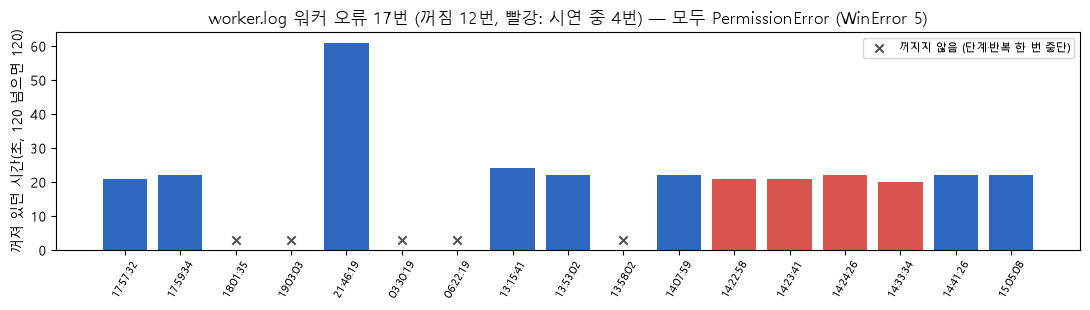

In [6]:
L = WORKER_LOG.read_text(encoding='utf-8', errors='replace').splitlines()
TS = re.compile(r'^\[(\d\d:\d\d:\d\d)\] ')
anchor = next(i for i, l in enumerate(L) if '단계 시작 · 요청 #21' in l)


def sec_of(hms):
    h, m, s = map(int, hms.split(':'))
    return h * 3600 + m * 60 + s


ev = []
for i, l in enumerate(L):
    m = re.match(r'^\[(\d\d:\d\d:\d\d)\] 워커 오류: ', l)
    if not m:
        continue
    j = i + 1
    while j < len(L) and not TS.match(L[j]):
        j += 1
    block = '\n'.join(L[i:j])
    types = list(dict.fromkeys(re.findall(r'^\s*(\w+(?:Error|Exception))\b', block, re.M)))
    funcs = re.findall(r', in (\w+)\n', block + '\n')
    nxt = next((k for k in range(j, len(L)) if TS.match(L[k]) and '워커 시작' in L[k]), None)
    down = (sec_of(L[nxt][1:9]) - sec_of(m.group(1))) % 86400 if nxt is not None else np.nan
    win = re.search(r'WinError (\d+)', block)
    died = 'During handling of the above exception' in block
    ev.append(dict(line=i + 1, time=m.group(1), error=', '.join(types), winerror=win.group(1) if win else '',
                   at=funcs[-1] if funcs else '', called_from=' → '.join(funcs[-3:-1]), died=died,
                   restart=L[nxt][1:9] if died and nxt is not None else '', down_sec=down if died else np.nan,
                   in_demo=(i > anchor) and sec_of(m.group(1)) <= sec_of(DEMO_END.strftime('%H:%M:%S'))))
E = pd.DataFrame(ev)
E.to_csv(OUT_DIR / 'ue_worker_errors.csv', index=False, encoding='utf-8-sig')
display(E)
print('워커 오류', len(E), '번, 종류:', E.error.value_counts().to_dict(), '| 오류 난 함수:', E['at'].value_counts().to_dict())
print('워커가 꺼진 오류', int(E.died.sum()), '번, 꺼지지 않은 오류', int((~E.died).sum()), '번')
print('시연 중', int(E.in_demo.sum()), '번 (꺼짐', int(E[E.in_demo].died.sum()), '번):', E[E.in_demo].time.tolist())
dd = E[E.died & (E.down_sec < 120)]
print('꺼진 뒤 다시 켜질 때까지(2분 이내만,', len(dd), '번):', dd.down_sec.min(), '~', dd.down_sec.max(), '초, 평균', round(dd.down_sec.mean(), 1), '초')
print('시연 중 꺼져 있던 시간 합:', E[E.in_demo].down_sec.sum(), '초')

fig, ax = plt.subplots(figsize=(11, 3.2))
x = np.arange(len(E))
y = E.down_sec.clip(upper=120).fillna(0)
col = np.where(E.in_demo, '#d9534f', '#2f69bf')
ax.bar(x, y, color=col)
ax.scatter(x[~E.died.values], np.zeros((~E.died).sum()) + 3, marker='x', color='#555', label='꺼지지 않음 (단계·반복 한 번 중단)')
ax.set_xticks(x)
ax.set_xticklabels(E.time, rotation=60, fontsize=8)
ax.set_ylabel('꺼져 있던 시간(초, 120 넘으면 120)')
ax.legend(fontsize=8, loc='upper right')
ax.set_title(f'worker.log 워커 오류 {len(E)}번 (꺼짐 {int(E.died.sum())}번, 빨강: 시연 중 {int(E.in_demo.sum())}번) — 모두 {E.error.iloc[0]} (WinError {E.winerror.iloc[0]})')
plt.tight_layout()
plt.savefig(OUT_DIR / 'ue_worker_errors.png', dpi=120)
plt.show()

원인과 고친 내용

- 모든 오류가 `save_state`의 `os.replace(tmp, STATE_PATH)`에서 난 `PermissionError [WinError 5]`이다. 워커는 상태 파일 `worker_state.json`을 2초마다, 그리고 로그 줄마다 바꿔 쓰는데, Windows에서는 그 순간 다른 프로세스가 파일을 잡고 있으면 바꿔 쓰기가 거부된다. 누가 잡고 있었는지(앱 화면이 읽는 중인지, OneDrive 동기화인지)는 확인하지 못했다.
- 예전 코드는 이 오류를 잡지 않아, 하던 단계가 중단되고 오류를 남기는 `log`까지 실패하면 워커 전체가 꺼졌다. 앱이 워커를 다시 띄울 때까지 요청이 멈췄다. 시연에서 A 요청(#21)이 이 때문에 밀렸다(위 "요청별 기다린 시간" 그래프의 "단계 밖").
- 11/04 수정: `save_state`가 실패하면 0.1·0.2·0.3·0.4초 기다리며 다시 해 보고, 5번 다 실패하면 이번 기록만 건너뛰고 워커는 계속 돈다(`worker.py` `SAVE_TRIES`, `SAVE_WAIT_SEC`). 건너뛴 횟수는 상태 파일의 `save_fail`과 worker.log "상태 파일 저장 5번 실패" 줄로 남는다. 고친 뒤 실제 앱에서 다시 확인한 기록은 아직 없다.

## 영상 장면 (원본 영상 시각)

영상을 1초 간격으로 보고 정리했다. 결과가 뜬 시각은 위 "시연 요청" 표의 "영상 시각(끝)"과 몇 초 차이가 날 수 있다(사용자가 다른 페이지에 있다가 돌아와서 본 경우).

| 원본 영상 시각 | 장면 |
|---|---|
| 0:00–1:03 | 게임 등록: 이름 "리치의 모험", 한 줄 소개, 판매 포인트, 레퍼런스 아트 입력 후 등록 |
| 1:04–1:15 | A 화면에서 스크린샷·판매 포인트·꼭 넣을 문구를 넣고 요청 |
| 1:16–4:30 | A 결과를 기다리는 동안 게임 목록(1:20, 2:19), A 화면(1:26, 2:21, 3:43, 4:27), 작업 대기열(1:28, 2:27, 3:53)로 9번 옮겨 다니며 확인 |
| 4:31–4:40 | A 결과 문구 확인 |
| 4:41–5:06 | B 요청 문장 입력, 변환 요청 |
| 5:45–6:02 | B 변환 결과(장면 태그·제목·부제) 확인 후 배너 생성 요청 |
| 6:53–7:20 | B 배너 결과 |
| 7:00–8:22 | 상세 페이지 화면: B 결과 등이 구역 선택지에 올라온 것을 확인 |
| 7:41–7:50 | C 화면: B 그림을 가져온 결과 |
| 8:23–8:48 | F 굿즈 목업: 머그컵 후보 중 고르기 |
| 8:49–8:59 | D 굿즈 배경 요청 (YR1n, 카페) |
| 10:46–10:54 | 작업 대기열: ⑥ IC-Light 단계가 끝나고 0건 |
| 10:55–10:59 | D 결과 |
| 11:00–11:10 | 상세 페이지: D 결과가 연출 사진 구역 선택지에 올라온 것을 확인 |
| 11:11 | 상세 페이지 만들기 요청 |
| 12:39–12:53 | 상세 페이지 완성 |

## 6개 항목 판단

### 1. 정확도와 적합도 — 규칙으로 잴 수 있는 것은 잘 맞추고, 내용이 사진과 맞는지는 못 잡는다

- 근거 (기존 실험, README "주요 결과"): A 문구 규칙 통과 냥기사 0.867·KayKit 1.00·0x72 0.800(10·13), 꼭 넣을 문구 빈칸 틀 1.000(25), A·B 형식 준수 1.00(08), 상세 페이지 구역 문구 12/12(21), B 글자 대비 WCAG 12/12(07), F 그림 유사도 0.941(14), D R1n 굿즈 SSIM 0.993(16).
- 근거 (시연, "시연 결과 문구와 자동 검사" 셀)
  - A #21: 첫 생성은 "sns가 2문장", "꼭 넣을 문구가 따로 붙음" 두 문제로 실패했고, 다시 생성해 문제 0개로 끝났다. 꼭 넣을 문구 "신규출시게임"은 sns 문장 안에 들어갔다.
  - B #22: 요청 문장의 "붉은 달", "네크로맨서", "죽음의 군대"가 장면 태그(red moon, necromancer, undead army)로 옮겨졌고, 부제는 요청 문장 끝 "지금 바로 만나보세요"를 그대로 썼다. #23 글자 대비는 기준 3.0을 넘었다.
  - 상세 페이지 #27 연출 사진 문구: "머그컵 위에 놓인 네크로맨서 리치 굿즈가 아침 햇살에 반짝이고 있어요."는 굿즈 자체가 머그컵인데 컵 위에 굿즈가 놓였다고 썼다. 문장 수·존댓말 검사는 통과했다.
- 판단: 형식, 꼭 넣을 문구, 존댓말, 글자 대비, 굿즈 보존처럼 코드로 검사하는 항목은 높게 맞춘다. 문구가 사진 내용과 맞는지와 말투 요청("친근하게")을 따랐는지는 검사하지 않는다(`textcfg.py`에서 말투는 프롬프트에만 들어감). 시연에서도 이 빈틈으로 어긋난 문장이 그대로 나왔다.
- C는 시연에서 새로 만들지 않고 B 그림을 가져왔다(#24). 새로 등록한 "리치의 모험"은 LoRA와 그림체 태그가 없어, 그림체는 24번의 기본 설정 결과(게임별 설정보다 낮음, 냥기사 0.718 → 0.639)를 따른다고 본다.

### 2. 일관성과 안정성 — 내용은 일관되고, 서비스는 워커가 꺼지는 문제가 있었다(고침, 재확인 필요)

- 근거: A #21 후보 5개 모두 "붉은 달", "네크로맨서", "신규출시게임"을 담았다("시연 결과 문구와 자동 검사" 셀). D #26은 Y 첫 시도에서 검은 띠가 나왔고, 자동으로 seed를 바꿔 두 번째에 통과했다(20의 다시 생성 방식이 앱에서 동작). 기존 실험에서 A 후보를 8개로 늘리면 오히려 0.889 → 0.844로 떨어져 4개를 유지했다(23).
- 근거: worker.log 워커 오류 17번이 모두 같은 원인(상태 파일 저장 `PermissionError`)이고, 그중 12번은 워커가 꺼졌다. 시연 중에는 4번 나서 4번 모두 꺼졌고, 꺼질 때마다 20~22초 뒤 다시 켜졌다("워커 오류" 셀).
- 판단: 같은 입력에서 주제와 꼭 넣을 문구는 후보마다 유지되고, 알려진 실패(Y 검은 띠)는 자동으로 다시 시도한다. 반면 앱 자체는 시연 중 워커가 4번 꺼져 안정적이지 않았다. 원인을 고쳤지만 고친 뒤 실제 앱에서 다시 확인해야 한다.

### 3. 응답 속도와 부하 처리 — 실제 생성은 짧지만 요청마다 모델 로드·준비가 더 길다

- 근거: "단계별 시간", "그래프: 요청별 기다린 시간 나누기" 셀. 워커 오류가 없던 요청(#22·#23·#26·#27)은 40.10~112.91초를 기다렸고, 그중 실제 생성은 5.56~22.07초다. 시연의 모델 단계 7개를 합치면 319.79초 중 실제 생성은 70.71초(0.221)다. A #21은 실제 생성 23.18초인데, 단계 밖 141.90초(워커가 꺼졌다 켜지며 실패한 시도) 때문에 198.41초를 기다렸다.
- 근거: 상세 페이지 1장 묶음 처리 80.9초 vs 페이지마다 모델을 새로 올리면 270.5초(21).
- 판단: 혼자 쓰는 도구로는 기다릴 만한 시간이지만, 단계마다 별도 프로세스를 띄우고 모델을 새로 올리는 구조라 기다리는 시간의 대부분이 생성이 아닌 준비다. 단계별 최대 VRAM이 Qwen 18.17GB, animagine 12.99GB라("단계별 시간" 셀) 둘을 함께 24GB GPU에 올려 둘 수 없어 고른 구조이고, 요청을 묶을수록 이득이 크다(21). 동시에 여러 요청이 들어오는 부하는 시연에서 시험하지 않았고, 21의 묶음 처리 결과만 있다.

### 4. 유저 중심 인터페이스 — 기능 사이 흐름은 이어지지만, 기다리는 동안 상태를 찾아다녀야 했다

- 근거 (영상): A 결과를 기다리는 3분 19초(원본 1:12~4:31) 동안 게임 목록, A 화면, 작업 대기열로 페이지를 9번 옮겨 다니며 확인했다(원본 1:20~4:27, "영상 장면" 표). B 변환 결과를 확인하고 바로 배너를 요청하는 2단계 흐름(5:45–6:02), B·D 결과가 상세 페이지 구역 선택지에 바로 올라오는 흐름(7:00–8:22, 11:00–11:10)이 이어진다.
- 근거 (기존): 올리는 그림의 크기·비율이 맞지 않으면 막고 필요한 크기를 안내한다(27). 화면 문구는 해요체로 통일했다(11/04).
- 판단: 등록 → 문구 → 배너 → 굿즈 → 상세 페이지가 앞 결과를 이어 쓰도록 짜여 있어 흐름은 자연스럽다. 다만 시연에서 사용자는 결과가 나왔는지 알려고 페이지를 옮겨 다녔다. 위 2번의 워커 오류로 기다림이 길어진 탓도 있지만, 진행 상황을 한곳에서 보기 어렵다는 점은 개선할 부분이다.

### 5. 서비스 완성도 — 처음부터 끝까지 한 번에 동작했다

- 근거: 시연 요청 7건이 모두 `done`으로 끝났다("시연 요청" 셀). 새 게임 등록부터 상세 페이지 완성까지 12분 53초 안에 끝났다(영상). 극단 입력 30개에서 상세 페이지 자동 검사 문제 0건(26). `start.bat` 한 번으로 설치부터 실행까지 된다(첫 설치 333초, 11/04).
- 판단: 실제로 쓸 수 있는 흐름이 갖춰졌다. 남은 문제는 2번의 워커 오류(고침, 재확인 필요)와 1번의 문구 내용 어긋남이다.

### 6. 제어 가능성 — 입력·옵션으로 방향을 바꿀 수 있고, 생성 전에 중간 결과를 고칠 수 있다

- 근거 (app.db 입력값): A는 판매 포인트·꼭 넣을 문구·말투(#21), B는 배너 크기와 변환된 장면 태그·제목·부제(#22·#23), F는 굿즈 종류와 목업 후보(#25), D는 방식(YR1n)과 장소(카페)(#26), 상세 페이지는 구역별 그림 선택과 문구 직접 입력(비우면 자동 생성)(#27)을 고를 수 있다. 그림체는 게임 등록의 태그·LoRA로 바꾼다.
- 근거: 시연에서는 B 장면 태그를 고치지 않고 그대로 생성했다(#23 입력 태그 = #22 변환 결과).
- 판단: 생성 전에 중간 결과(B 장면 태그)를 보고 고치거나, 상세 페이지 문구를 직접 넣는 식으로 방향을 바꿀 수 있다. 다만 말투와 내용 정확성은 검사가 없어서, 1번처럼 어긋난 문장은 사용자가 직접 찾아 고쳐야 한다.

### 정리

| 항목 | 판단 | 근거 셀·노트북 |
|---|---|---|
| 정확도와 적합도 | 규칙 항목은 높음, 내용·말투는 검사 없음 | 시연 결과 문구, 08·10·13·21·25 |
| 일관성과 안정성 | 내용 일관, 워커 꺼짐(고침, 재확인 필요) | 시연 결과 문구, 워커 오류, 20·23 |
| 응답 속도와 부하 처리 | 요청당 40~113초, 실제 생성은 그중 0.221 | 단계별 시간, 요청별 기다린 시간, 21 |
| 유저 중심 인터페이스 | 흐름 이어짐, 진행 확인이 불편 | 영상 장면, 27 |
| 서비스 완성도 | 끝까지 동작 | 시연 요청, 26 |
| 제어 가능성 | 입력·중간 결과로 조절 가능 | 시연 결과 문구, 영상 장면 |